In [1]:
import pandas as pd                                         # tables
import numpy as np                                          # math helpers

df = pd.read_parquet("../data/processed/features.parquet")  # feature set v2 from notebook 4

TARGET = "fantasy_points_ppr"                               # what we predict
ROLE_CUTOFF = 0.25                                          # real-role = played 25%+ of snaps over the last 3 games (Decision 3)
POSITIONS = ["QB", "RB", "WR", "TE"]                        # fixed order for every table

df.shape                                                    # check: same rows as notebook 4's final output

(38571, 35)

In [2]:
df = df[df["history_flag"] == "ok"].copy()                  # Decision 2: drop each player's first game of the season

train = df[df["season"].between(2020, 2024)]                # Decision 1: learn from 2020-2024
test = df[df["season"] == 2025]                             # graded once, at the end
live = df[df["season"] == 2026]                             # set aside for Phase 4

# for tuning later: learn on 2020-2023, check on 2024 (never tune on 2025)
tune_train = df[df["season"].between(2020, 2023)]           # tuning: training part
tune_val = df[df["season"] == 2024]                         # tuning: checking part

print(f"train {len(train):,} | test {len(test):,} | live {len(live):,}")              # row counts per split
print("real-role share of test:", round((test["offense_pct_last3"] >= ROLE_CUTOFF).mean(), 3))  # how much of test is real-role

train 25,873 | test 5,427 | live 3,071
real-role share of test: 0.754


In [3]:
def score(pred, model_name):                                # pred = predictions for every test row; returns MAE table rows
    err = (test[TARGET] - pred).abs()                       # absolute error per row: how many points we missed by
    groups = {                                              # the two player groups from Decision 3
        "all": pd.Series(True, index=test.index),           #   every test row
        "real_role": test["offense_pct_last3"] >= ROLE_CUTOFF,  #   only players with a real role
    }
    rows = []                                               # collect one row per (group, position)
    for group_name, mask in groups.items():                 # loop over the 2 player groups
        for pos in POSITIONS + ["ALL"]:                     # loop over each position, plus everyone combined
            m = mask if pos == "ALL" else mask & (test["position"] == pos)  # rows in this group and position
            rows.append({"model": model_name,               # which model or baseline
                         "players": group_name,             # all / real_role
                         "position": pos,                   # QB / RB / WR / TE / ALL
                         "mae": err[m].mean(),              # average points missed
                         "n": int(m.sum())})                # how many games it's based on
    return rows                                             # list of dicts -> becomes a table later

results = []                                                # every model's scores get added here

In [4]:
results += score(test["fantasy_points_ppr_last1"], "Baseline 1: last game")      # predict = last game's points
results += score(test["fantasy_points_ppr_last3"], "Baseline 2: last 3 avg")     # predict = average of last 3 games

table = pd.DataFrame(results)                               # turn the list of dicts into a table
table.pivot_table(index=["players", "position"],            # rows: group + position
                  columns="model", values="mae").round(2)   # columns: one per model; values: MAE

model               Baseline 1: last game  Baseline 2: last 3 avg
players   position                                               
all       ALL                        5.52                    4.72
          QB                         8.04                    6.99
          RB                         5.47                    4.70
          TE                         4.67                    3.88
          WR                         5.33                    4.58
real_role ALL                        6.55                    5.55
          QB                         8.52                    7.38
          RB                         7.42                    6.27
          TE                         5.14                    4.26
          WR                         6.33                    5.39

In [5]:
from sklearn.pipeline import make_pipeline                  # chains steps: fill blanks -> model
from sklearn.impute import SimpleImputer                    # fills blank values
from sklearn.linear_model import LinearRegression           # Model 1
from sklearn.ensemble import HistGradientBoostingRegressor  # Model 2 (handles blanks on its own)

ID_COLS = ["player_id", "player_display_name", "position", "team",     # identifiers: say which row is which; never model inputs
           "opponent_team", "season", "week", "history_flag"]
FEATURES = [c for c in df.columns if c not in ID_COLS + [TARGET]]      # everything else = the 26 features
print(len(FEATURES), "features")                                       # check: 26

def fit_per_position(make_model):                           # make_model = function that returns a fresh, untrained model
    pred = pd.Series(np.nan, index=test.index)              # empty predictions, one slot per test row
    models = {}                                             # keep each trained model (for feature importance later)
    for pos in POSITIONS:                                   # one model per position
        tr = train[train["position"] == pos]                # this position's 2020-2024 rows
        te = test["position"] == pos                        # which 2025 rows are this position
        cols = [c for c in FEATURES if tr[c].notna().any()] # skip features with no values at all for this position (e.g. EPA/att for WRs)
        model = make_model()                                # new untrained model
        model.fit(tr[cols], tr[TARGET])                     # learn: features -> points
        pred[te] = model.predict(test.loc[te, cols])        # predict this position's 2025 games (same columns)
        models[pos] = model                                 # save it; model.feature_names_in_ remembers which columns it used
    return pred, models                                     # predictions for all test rows + the 4 models

26 features


In [6]:
lin_pred, lin_models = fit_per_position(                    # train 4 linear models (QB, RB, WR, TE)
    lambda: make_pipeline(                                  # each one is a 2-step pipeline:
        SimpleImputer(strategy="median", add_indicator=True),  # 1) fill blanks with the training median + add "was blank" flags
        LinearRegression()))                                #    2) fit a straight-line model
results += score(lin_pred, "Linear regression")             # grade it the same way as the baselines

In [7]:
gb_pred, gb_models = fit_per_position(                      # train 4 gradient boosting models
    lambda: HistGradientBoostingRegressor(random_state=42)) # default settings; random_state = same result every run
results += score(gb_pred, "Gradient boosting")              # grade it the same way

In [8]:
table = pd.DataFrame(results)                               # every score so far as one table
comp = table.pivot_table(index=["players", "position"],     # rows: group + position
                         columns="model", values="mae").round(2)  # columns: one per model

base, best = comp["Baseline 2: last 3 avg"], comp["Linear regression"]  # the bar and the main model
comp["LR vs B2 (pts)"] = (base - best).round(2)             # points better (positive = model wins)
comp["LR vs B2 (%)"] = ((base - best) / base * 100).round(1)  # percent better (fair across positions)

table.to_csv("../reports/tables/model_comparison.csv", index=False)  # save for the poster (checkpoint 3)
comp.to_csv("../reports/tables/model_comparison_wide.csv")  # pivoted table with LR vs B2 columns (keep the index: it holds group + position)
comp                                                        # show it

model               Baseline 1: last game  Baseline 2: last 3 avg  \
players   position                                                  
all       ALL                        5.52                    4.72   
          QB                         8.04                    6.99   
          RB                         5.47                    4.70   
          TE                         4.67                    3.88   
          WR                         5.33                    4.58   
real_role ALL                        6.55                    5.55   
          QB                         8.52                    7.38   
          RB                         7.42                    6.27   
          TE                         5.14                    4.26   
          WR                         6.33                    5.39   

model               Gradient boosting  Linear regression  LR vs B2 (pts)  \
players   position                                                         
all       ALL                    4.54               4.44            0.28   
          QB                     6.65               6.44            0.55   
          RB                     4.59               4.49            0.21   
          TE                     3.77               3.62            0.26   
          WR                     4.37               4.31            0.27   
real_role ALL                    5.21               5.11            0.44   
          QB                     6.93               6.65            0.73   
          RB                     5.88               5.78            0.49   
          TE                     4.05               3.91            0.35   
          WR                     5.03               5.01            0.38   

model               LR vs B2 (%)  
players   position                
all       ALL                5.9  
          QB                 7.9  
          RB                 4.5  
          TE                 6.7  
          WR                 5.9  
real_role ALL                7.9  
          QB                 9.9  
          RB                 7.8  
          TE                 8.2  
          WR                 7.1

In [9]:
val_scores = []                                              # MAE per model on the 2024 check
for name, make_model in [("Linear regression",               # same two models as cells 5-6
                          lambda: make_pipeline(SimpleImputer(strategy="median", add_indicator=True), LinearRegression())),
                         ("Gradient boosting",
                          lambda: HistGradientBoostingRegressor(random_state=42))]:
    for pos in POSITIONS:                                    # one model per position, like before
        tr = tune_train[(tune_train["position"] == pos)]     # learn on 2020-2023
        va = tune_val[(tune_val["position"] == pos) &        # check on 2024 ...
                      (tune_val["offense_pct_last3"] >= ROLE_CUTOFF)]  # ... real-role players only (headline group)
        cols = [c for c in FEATURES if tr[c].notna().any()]  # skip all-blank features for this position
        model = make_model().fit(tr[cols], tr[TARGET])       # train a fresh model
        mae = (va[TARGET] - model.predict(va[cols])).abs().mean()  # average points missed on 2024
        val_scores.append({"model": name, "position": pos, "mae": round(mae, 2)})  # save the score

pd.DataFrame(val_scores).pivot(index="position", columns="model", values="mae")  # side-by-side on 2024

model,Gradient boosting,Linear regression
position,,
QB,6.58,6.27
RB,5.55,5.49
TE,3.97,3.86
WR,5.27,5.22


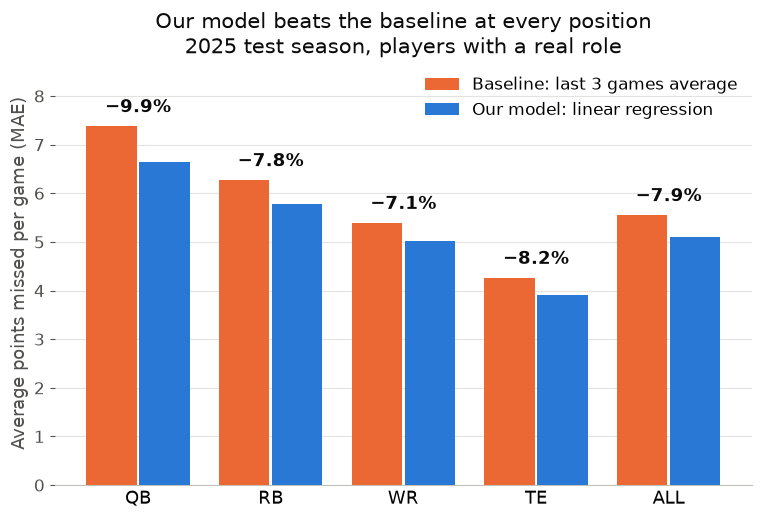

In [10]:
import matplotlib.pyplot as plt                              # plotting library

ORDER = ["QB", "RB", "WR", "TE", "ALL"]                      # left-to-right order of the bar groups
rr = comp.loc["real_role"].reindex(ORDER)                    # real-role rows only (the headline), in that order
base = rr["Baseline 2: last 3 avg"]                          # baseline MAE per position
model = rr["Linear regression"]                              # our model's MAE per position
gain = (base - model) / base * 100                           # % improvement per position

x = np.arange(len(ORDER))                                    # x positions 0..4, one per group
w = 0.38                                                     # width of each bar
fig, ax = plt.subplots(figsize=(9, 5.5))                     # blank figure, 9 x 5.5 inches

ax.bar(x - w/2 - 0.01, base, width=w, color="#eb6834",       # baseline bars, left of center, orange
       label="Baseline: last 3 games average", zorder=3)     # legend name; zorder=3 draws bars above gridlines
ax.bar(x + w/2 + 0.01, model, width=w, color="#2a78d6",      # model bars, right of center, blue (the 0.01 leaves a small gap)
       label="Our model: linear regression", zorder=3)       # legend name

for i in range(len(ORDER)):                                  # one label per group (not on every bar)
    ax.text(x[i], base.iloc[i] + 0.2, f"−{gain.iloc[i]:.1f}%",  # text just above the taller bar, e.g. "−7.9%"
            ha="center", va="bottom", fontsize=13,           # centered over the pair
            fontweight="bold", color="#0b0b0b")              # bold, dark text

ax.set_xticks(x, ORDER, fontsize=13)                         # position names under each group
ax.set_ylabel("Average points missed per game (MAE)",        # y-axis label in plain words
              fontsize=13, color="#52514e")                  # gray so it doesn't compete with the data
ax.set_title("Our model beats the baseline at every position\n"   # title states the finding
             "2025 test season, players with a real role",        # subtitle says what data it is
             fontsize=15, loc="center", color="#0b0b0b")             # left-aligned
ax.set_ylim(0, base.max() * 1.18)                            # start at 0 (bars must); leave room for the % labels
ax.tick_params(axis="y", labelsize=12, colors="#52514e")     # y numbers: readable, gray
ax.tick_params(axis="x", length=0)                           # no tick marks under the groups
ax.grid(axis="y", color="#e4e3df", linewidth=0.8, zorder=0)  # faint horizontal gridlines behind bars
for side in ["top", "right", "left"]:                        # remove 3 of the 4 box edges
    ax.spines[side].set_visible(False)                       # cleaner look
ax.spines["bottom"].set_color("#c3c2b7")                     # light baseline at 0
ax.legend(frameon=False, fontsize=12, loc="upper right")     # legend with no box

fig.savefig("../reports/figures/mae_by_position.png",        # save for the poster (checkpoint 3)
            dpi=200, bbox_inches="tight", facecolor="white") # sharp enough to print; trim extra margin
plt.show()                                                   # also display it in the notebook